# ConvNeXt V1 — A ConvNet for the 2020s

**Paper**: Liu, Z., Mao, H., Wu, C.-Y., Feichtenhofer, C., Darrell, T., & Xie, S. (2022).  
**"A ConvNet for the 2020s"**  
CVPR 2022 · arXiv:2201.03545  
Meta AI Research

---

## Why This Paper Matters

By 2021, Vision Transformers (ViT, Swin) were outperforming CNN architectures on most benchmarks. The narrative was: **"attention is all you need"** — transformers win because of their global attention mechanism.

ConvNeXt V1 challenged this narrative by asking a different question: **what happens if we give a ResNet all the same design choices as Swin Transformer?**

The answer: a pure CNN matches Swin at every scale — same accuracy, comparable FLOPs, no attention required.  
The improvements came entirely from **training procedure** and **architectural micro-choices**, not from the attention mechanism itself.

ConvNeXt-L achieves **84.3% top-1 on ImageNet** (vs Swin-L's 84.2%).  
ConvNeXt-XL reaches **87.0%** with ImageNet-22K pretraining.

> 📄 **Paper:** Liu, Mao, Wu, Feichtenhofer, Darrell & Xie (2022). A ConvNet for the 2020s. CVPR 2022.
> 🔗 **Link:** <https://arxiv.org/abs/2201.03545>
> 🧩 **Implementation:** `hale_core/nn/vision/cnn/convnext_v1.py` (reproduced in full in §4 - runs with plain PyTorch)

**How this notebook is organised:** 1. paper & idea · 2. architecture diagrams (Mermaid, ASCII, matplotlib) ·
3. key ideas · 4. the full architecture in pure PyTorch · 5. build & run · 6. parameters vs paper & gradient flow ·
7. equivalence with the library · 8. feature maps · references.

## 2. Architecture diagram

Colours: <span style="color:#d48806">■ input</span> · <span style="color:#1f77b4">■ stages</span> ·
<span style="color:#8e44ad">■ blocks / operations</span> · <span style="color:#c0392b">■ outputs</span>.
(Mermaid renders on GitHub, in JupyterLab ≥ 4.1 and VS Code; an ASCII and a matplotlib version follow.)

```mermaid
flowchart TB
  IN["image (B, 3, 224, 224)"]:::io --> STEM["patchify stem: conv 4×4 /4 · LayerNorm → 96"]:::stage
  STEM --> S1["stage 1 ×3 (96) /4"]:::stage --> D1["LN · conv 2×2 /2"]:::block --> S2["stage 2 ×3 (192) /8"]:::stage
  S2 --> D2["downsample"]:::block --> S3["stage 3 ×9 (384) /16"]:::stage --> D3["downsample"]:::block --> S4["stage 4 ×3 (768) /32"]:::stage
  S4 --> GAP["avg pool · LayerNorm"]:::block --> OUT
  subgraph BLK["ConvNeXt block"]
    direction LR
    X["x"] --> DW["7×7 depthwise"]:::block --> LN["LayerNorm"]:::block --> FC1["1×1 → 4C · GELU"]:::block --> FC2["1×1 → C"]:::block --> LS["layer scale γ"]:::block --> ADD(("+ drop-path"))
    X --> ADD
  end
  S1 -.-> BLK
  OUT["BackboneOutput<br/>pooled_output (B, embed_dim)<br/>feature_maps finest → coarsest<br/>patch_tokens = None"]:::out
  classDef io fill:#fff7e6,stroke:#d48806,color:#222
  classDef stage fill:#eaf2fb,stroke:#1f77b4,color:#222
  classDef block fill:#f1e6f8,stroke:#8e44ad,color:#222
  classDef out fill:#fdecea,stroke:#c0392b,color:#222
```

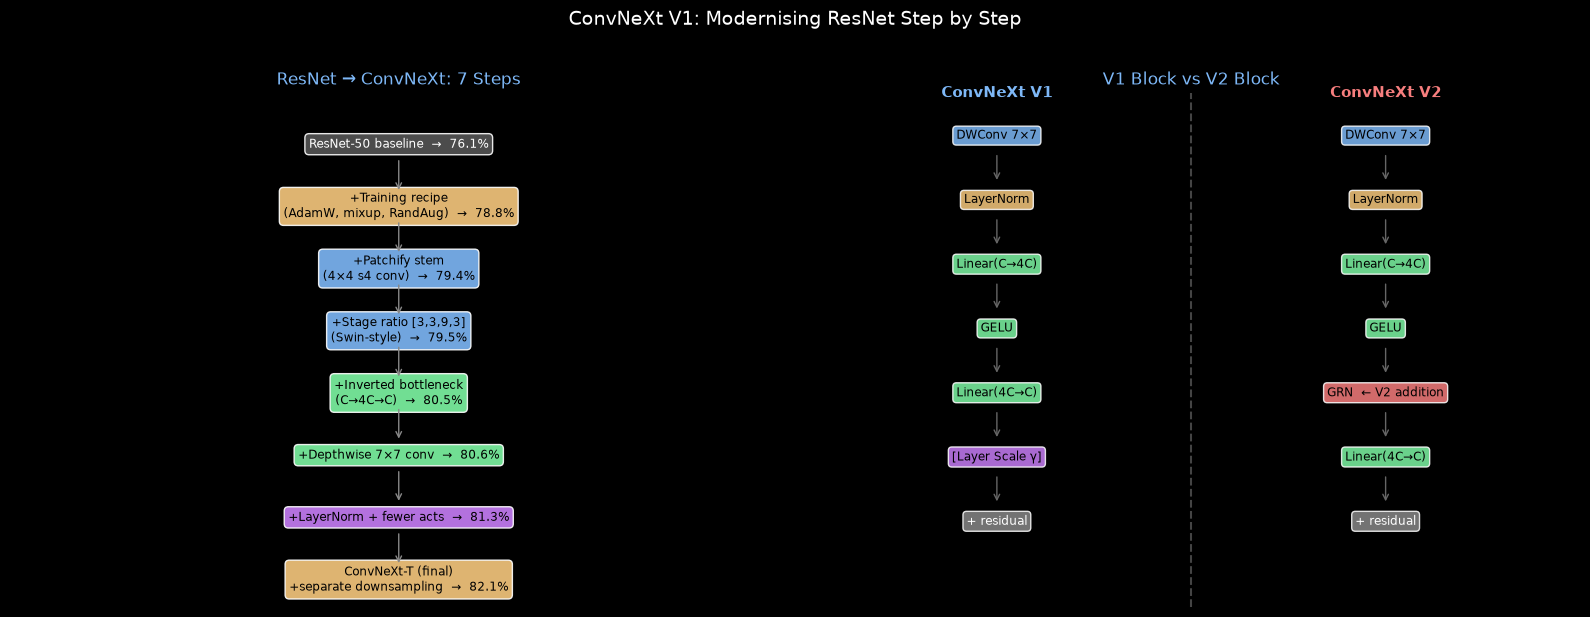

In [1]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np

plt.style.use('dark_background')
ACCENT = '#7EB8F7'
RED    = '#F77E7E'
GREEN  = '#7EF7A4'
GOLD   = '#F7C97E'
PURPLE = '#C87EF7'

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('ConvNeXt V1: Modernising ResNet Step by Step', fontsize=14, color='white', y=1.02)

# --- Panel 1: The modernisation journey ---
ax = axes[0]
ax.set_xlim(0, 6)
ax.set_ylim(0, 15)
ax.axis('off')
ax.set_title('ResNet → ConvNeXt: 7 Steps', color=ACCENT)

# Each step: (accuracy gain, label, color)
journey = [
    ('ResNet-50 baseline', 76.1, '#555'),
    ('+Training recipe\n(AdamW, mixup, RandAug)', 78.8, GOLD),
    ('+Patchify stem\n(4×4 s4 conv)', 79.4, ACCENT),
    ('+Stage ratio [3,3,9,3]\n(Swin-style)', 79.5, ACCENT),
    ('+Inverted bottleneck\n(C→4C→C)', 80.5, GREEN),
    ('+Depthwise 7×7 conv', 80.6, GREEN),
    ('+LayerNorm + fewer acts', 81.3, PURPLE),
    ('ConvNeXt-T (final)\n+separate downsampling', 82.1, GOLD),
]

y_positions = np.linspace(13.5, 0.8, len(journey))
for (label, acc, col), yp in zip(journey, y_positions):
    ax.text(3, yp, f'{label}  →  {acc:.1f}%', ha='center', va='center', fontsize=8.5,
            color='black' if col not in ['#555'] else 'white',
            bbox=dict(boxstyle='round,pad=0.35', facecolor=col, alpha=0.9))

for yp0, yp1 in zip(y_positions[:-1], y_positions[1:]):
    ax.annotate('', xy=(3, yp1+0.4), xytext=(3, yp0-0.4),
                arrowprops=dict(arrowstyle='->', color='#888'))

# --- Panel 2: V1 vs V2 block comparison ---
ax = axes[1]
ax.set_xlim(0, 8)
ax.set_ylim(0, 12)
ax.axis('off')
ax.set_title('V1 Block vs V2 Block', color=ACCENT)

# V1 block
v1_steps = [
    (2, 11, 'DWConv 7×7', ACCENT),
    (2, 9.5, 'LayerNorm', GOLD),
    (2, 8, 'Linear(C→4C)', GREEN),
    (2, 6.5, 'GELU', GREEN),
    (2, 5, 'Linear(4C→C)', GREEN),
    (2, 3.5, '[Layer Scale γ]', PURPLE),
    (2, 2, '+ residual', '#888'),
]
# V2 block
v2_steps = [
    (6, 11, 'DWConv 7×7', ACCENT),
    (6, 9.5, 'LayerNorm', GOLD),
    (6, 8, 'Linear(C→4C)', GREEN),
    (6, 6.5, 'GELU', GREEN),
    (6, 5, 'GRN  ← V2 addition', RED),
    (6, 3.5, 'Linear(4C→C)', GREEN),
    (6, 2, '+ residual', '#888'),
]

ax.text(2, 11.9, 'ConvNeXt V1', ha='center', color=ACCENT, fontsize=11, fontweight='bold')
ax.text(6, 11.9, 'ConvNeXt V2', ha='center', color=RED, fontsize=11, fontweight='bold')

for steps in [v1_steps, v2_steps]:
    for x, y, label, col in steps:
        ax.text(x, y, label, ha='center', va='center', fontsize=8.5,
                color='black' if col not in ['#888'] else 'white',
                bbox=dict(boxstyle='round,pad=0.3', facecolor=col, alpha=0.85))
    ys = [s[1] for s in steps]
    for y0, y1 in zip(ys[:-1], ys[1:]):
        ax.annotate('', xy=(steps[0][0], y1+0.4), xytext=(steps[0][0], y0-0.4),
                    arrowprops=dict(arrowstyle='->', color='#666'))

# Dividing line
ax.axvline(4, color='#444', linewidth=1.5, linestyle='--')

plt.tight_layout()
plt.show()

## 3. Key ideas

## Mathematical Formulation

### Inverted Bottleneck

Unlike ResNet (where the bottleneck *reduces* channels: $C \to C/4 \to C$), ConvNeXt uses an **inverted bottleneck** (expand then contract):

$$\text{Inverted Bottleneck: } C \xrightarrow{\text{Linear}} 4C \xrightarrow{\text{GELU}} 4C \xrightarrow{\text{Linear}} C$$

This mirrors MobileNetV2 (Howard et al. 2018) and ViT's MLP blocks.  
The 4× expansion ratio maximises expressiveness per block without increasing output channels.

### Layer Scale (for Large/XLarge variants)

A per-channel learnable scalar $\gamma \in \mathbb{R}^C$ (initialised to $10^{-6}$) multiplies the block output before the residual add:

$$y = x + \gamma \odot f(x)$$

Near-zero initialisation makes each block start as near-identity, improving gradient flow in very deep networks. ConvNeXt V2 replaces this with **GRN** (Global Response Normalisation).

### V1 vs V2: What GRN Adds

**V1 (this notebook)**: no GRN. Layer Scale for large variants. FCMAE pre-training showed V1 blocks collapse features during masked autoencoding (dead filters).

**V2 (Woo et al. 2023)**: adds GRN after GELU:
$$\text{GRN: } x_c \leftarrow \gamma_c \cdot \frac{\|x_c\|_2}{\mathbb{E}[\|x_c\|_2]} \cdot x_c + \beta_c + x_c$$

GRN introduces inter-channel competition — channels with large spatial norms scale up; weak channels are suppressed. This prevents feature collapse during FCMAE self-supervised pre-training.

## 4. The architecture in pure PyTorch

Below is the **complete implementation** used by HaleBlocks (`hale_core/nn/vision/cnn/convnext_v1.py`), one top-level
definition per cell, with its original comments and docstrings. Only the `hale_core` imports were replaced by the
two foundation cells (the `BackboneOutput` / `BaseVisionBackbone` contract and a 10-line registry), so this notebook
runs anywhere PyTorch is installed. §7 checks it is bit-for-bit the library implementation.

<details><summary>Module docstring of <code>cnn/convnext_v1.py</code></summary>

```text
ConvNeXt V1 Vision Backbones
=============================

Implements the ConvNeXt V1 family (Liu et al. 2022, "A ConvNet for the 2020s",
CVPR 2022, https://arxiv.org/abs/2201.03545).

Design philosophy
-----------------
ConvNeXt V1 is a pure CNN redesigned to systematically match Swin Transformer.
Starting from ResNet-50, the authors apply a sequence of design improvements:

  1. Patchify stem: 4×4 stride-4 conv (no 7×7 + maxpool).
  2. Stage compute ratio: [3,3,9,3] matching Swin's stage distribution.
  3. Inverted bottleneck: expand channels 4× inside each block (like MobileNet).
  4. Depthwise 7×7 conv: matches Swin's 7×7 local window receptive field.
  5. Fewer activations: only one GELU (after the expansion linear).
  6. Fewer normalisations: only one LayerNorm per block (before the linear layers).
  7. LayerNorm instead of BatchNorm: matches transformer-style normalisation.
  8. Separate downsampling: LayerNorm + 2×2 stride-2 conv between stages.
  9. Layer Scale: learnable per-channel scalar γ (init 1e-6) stabilises training
     of deep networks; enabled for large/xlarge.

Block structure (ConvNeXtV1Block)
----------------------------------
  input [B, C, H, W]  (channels-first)
    → DWConv(C, 7×7, groups=C)
    → permute to [B, H, W, C]
    → LayerNorm(C, ε=1e-6)
    → Linear(C → 4C)
    → GELU
    → Linear(4C → C)
    → * layer_scale_gamma  (if layer_scale_init_value > 0)
    → permute back to [B, C, H, W]
    → stochastic depth + residual

Difference from V2
------------------
  V1: no GRN (Global Response Normalization).
  V2: adds GRN after the wide (4C) GELU layer.
  V1: optional Layer Scale (per-channel scalar).
  V2: replaces Layer Scale with GRN.

Registered names
----------------
  convnext_v1_tiny   — depths=[3,3,9,3],   dim=96
  convnext_v1_small  — depths=[3,3,27,3],  dim=96
  convnext_v1_base   — depths=[3,3,27,3],  dim=128
  convnext_v1_large  — depths=[3,3,27,3],  dim=192  (layer_scale enabled)
  convnext_v1_xlarge — depths=[3,3,27,3],  dim=256  (layer_scale enabled)

Citations
---------
  Liu, Z., Mao, H., Wu, C.-Y., Feichtenhofer, C., Darrell, T., & Xie, S. (2022).
  A ConvNet for the 2020s. CVPR.  arXiv:2201.03545

  Woo, S. et al. (2023). ConvNeXt V2: Co-designing and Scaling ConvNets with
  Masked Autoencoders. CVPR.  arXiv:2301.00808
```
</details>

In [2]:
from __future__ import annotations

# Everything below is plain PyTorch - no hale_core import is needed to run this notebook.
import math
from abc import ABC, abstractmethod
from copy import deepcopy
from dataclasses import dataclass, field
from typing import Any, Callable, Optional, Type, TypeVar, Union

import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(0)
torch.set_num_threads(min(4, torch.get_num_threads()))
print("torch", torch.__version__)

torch 2.14.1


### 4.1 Foundation: the backbone contract (`base.py`) and a local registry

In [3]:
@dataclass
class BackboneOutput:
    """Standard output container for all vision backbones.

    Attributes
    ----------
    pooled_output:
        Global image representation after spatial pooling. Shape [B, embed_dim].
        Used by: classification heads, VLM projectors, action encoders.

    patch_tokens:
        Per-patch (or per-pixel) feature tokens BEFORE pooling.
        Shape [B, N, embed_dim] for ViT-style; None for pure CNNs.
        Used by: VLM cross-attention, dense grounding.

    feature_maps:
        Multi-scale spatial feature tensors, ordered finest → coarsest.
        Each element: [B, C_i, H/s_i, W/s_i] where s_i is the stride.
        Used by: FPN, BEV encoder, depth heads.

    attentions:
        Optional list of attention weight tensors from each transformer block.
        Used for interpretability (attention rollout, DINO self-supervised heads).
    """

    pooled_output: torch.Tensor                          # [B, embed_dim]
    patch_tokens:  Optional[torch.Tensor] = None        # [B, N, D] or None
    feature_maps:  list[torch.Tensor] = field(default_factory=list)  # multi-scale
    attentions:    Optional[list[torch.Tensor]] = None  # transformer attention maps


class BaseVisionBackbone(ABC, nn.Module):
    """Abstract base for all vision backbones.

    Subclasses MUST define:
      - arch_name  (str): human-readable identifier, e.g. "resnet50"
      - embed_dim  (int): dimension of pooled_output
      - feature_dims (list[int]): channel counts for each feature map scale
      - forward(x) -> BackboneOutput

    Args:
        img_size:   Expected input spatial resolution (height == width assumed).
        in_chans:   Number of input image channels (default 3 for RGB).
        drop_rate:  Dropout probability applied to the final pooled features.
        out_indices: Which multi-scale feature stages to include in BackboneOutput.
                     E.g. [0, 1, 2, 3] returns all four scales; [2, 3] returns
                     only the two coarsest.  Default returns all available.
    """

    # ── Class-level metadata — override in each subclass ─────────────────────
    arch_name:    str        = "base"
    embed_dim:    int        = 0
    feature_dims: list[int] = []   # channel counts per stage, finest→coarsest

    def __init__(
        self,
        img_size:    int        = 224,
        in_chans:    int        = 3,
        drop_rate:   float      = 0.0,
        out_indices: list[int] | None = None,
    ) -> None:
        super().__init__()
        self.img_size    = img_size
        self.in_chans    = in_chans
        self.drop_rate   = drop_rate
        self.out_indices = out_indices  # None = return all stages

    @abstractmethod
    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Run the backbone on a batch of images.

        Args:
            x: Float32 tensor of shape [B, in_chans, H, W].
               Typically ImageNet-normalised (mean=[0.485,0.456,0.406],
               std=[0.229,0.224,0.225]).

        Returns:
            BackboneOutput with pooled_output, patch_tokens, feature_maps.
        """
        ...

    # ── Convenience helpers ───────────────────────────────────────────────────

    def num_parameters(self, trainable_only: bool = False) -> int:
        """Count model parameters.

        Args:
            trainable_only: If True, count only parameters with requires_grad=True.

        Returns:
            Integer parameter count.
        """
        params = self.parameters()
        if trainable_only:
            params = (p for p in params if p.requires_grad)
        return sum(p.numel() for p in params)

    def freeze_all(self) -> None:
        """Freeze all parameters (no gradient computation).

        Useful when using the backbone as a frozen feature extractor
        inside a VLM or action decoder that only trains the head.
        """
        for p in self.parameters():
            p.requires_grad_(False)

    def unfreeze_all(self) -> None:
        """Unfreeze all parameters."""
        for p in self.parameters():
            p.requires_grad_(True)

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze all stages from 0 up to and including `stage`.

        Useful for fine-tuning: freeze the early feature extractor stages
        and only fine-tune the later stages.  The exact meaning of "stage"
        is backbone-specific; see each subclass's docstring.

        Args:
            stage: Stage index (0-based).  Stages 0..stage are frozen.
        """
        raise NotImplementedError(
            f"{self.__class__.__name__} does not implement freeze_up_to_stage()"
        )

    def __repr__(self) -> str:
        return (
            f"{self.__class__.__name__}("
            f"arch={self.arch_name}, "
            f"embed_dim={self.embed_dim}, "
            f"img_size={self.img_size}, "
            f"params={self.num_parameters():,})"
        )

In [4]:
# A minimal stand-in for hale_core.nn.vision.registry: same decorator name and behaviour, so the
# library source below runs unchanged. Re-registration is allowed so cells can be re-run.
_VISION_BACKBONES: dict[str, type] = {}
T = TypeVar("T")


def register_vision_backbone(name: str) -> Callable[[T], T]:
    """Class decorator: store ``cls`` under ``name`` (lower-case)."""
    def decorator(cls: T) -> T:
        _VISION_BACKBONES[name.lower()] = cls
        return cls
    return decorator


def build_vision_backbone(name: str, **kwargs: Any) -> "BaseVisionBackbone":
    """Instantiate a backbone registered in this notebook."""
    return _VISION_BACKBONES[name.lower()](**kwargs)


def list_vision_backbones() -> list[str]:
    return sorted(_VISION_BACKBONES)

### Shared building blocks from `cnn/convnext.py` used by this family: `ConvNeXtV2Block`, `ConvNeXtBase`

In [5]:
class LayerNorm2d(nn.LayerNorm):
    """LayerNorm adapted for channels-first (B, C, H, W) spatial tensors.

    PyTorch's nn.LayerNorm expects the normalised dims to be the last dims.
    This wrapper transposes to channels-last before normalising, then transposes back.
    This is the standard approach used by ConvNeXt and many modern CNNs.
    """

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # x: [B, C, H, W]
        x = x.permute(0, 2, 3, 1)          # → [B, H, W, C]
        x = super().forward(x)              # LayerNorm over last dim C
        return x.permute(0, 3, 1, 2)       # → [B, C, H, W]


class GRN(nn.Module):
    """Global Response Normalization (GRN) — the key addition in ConvNeXt V2.

    GRN introduces cross-channel feature competition: channels with large global
    norms suppress channels with small global norms.  This discourages feature
    collapse (redundant channels learning the same thing) during masked autoencoding.

    Formulation (Woo et al. 2023, Eq. 1–3):
        gx = ‖x‖₂ over H, W dims          → [B, 1, 1, C]  (global spatial norm)
        nx = gx / E[gx]                    → normalised norms (E over C)
        output = x * nx + gamma * x + beta
    where gamma and beta are learned per-channel parameters (shape [C]).

    Args:
        dim: Number of feature channels (C).

    Shape:
        Input / Output: [B, H, W, C]  (channels-last convention inside blocks)
    """

    def __init__(self, dim: int) -> None:
        super().__init__()
        # Learnable scale and bias initialised to 0 (start as identity)
        self.gamma = nn.Parameter(torch.zeros(1, 1, 1, dim))
        self.beta  = nn.Parameter(torch.zeros(1, 1, 1, dim))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        # Global spatial L2 norm per channel: [B, 1, 1, C]
        gx = x.norm(p=2, dim=(1, 2), keepdim=True)
        # Normalise across the channel dimension
        nx = gx / (gx.mean(dim=-1, keepdim=True) + 1e-6)
        # Scale and shift
        return self.gamma * (x * nx) + self.beta + x


class ConvNeXtV2Block(nn.Module):
    """Single ConvNeXt V2 residual block.

    Sequence: DWConv → LayerNorm → Linear(4x expand) → GeLU → GRN → Linear(contract)
    with a residual connection.  All linear ops are implemented as pointwise 1×1
    convolutions via nn.Linear on the transposed tensor (channels-last) for clarity.

    Args:
        dim:        Number of input (and output) channels.
        drop_path:  Stochastic depth drop probability (0 = disabled).
    """

    def __init__(self, dim: int, drop_path: float = 0.0) -> None:
        super().__init__()

        # Depthwise 7×7 conv — processes spatial context within each channel
        self.dwconv = nn.Conv2d(dim, dim, kernel_size=7, padding=3, groups=dim)
        # LayerNorm in channels-last space (after transpose)
        self.norm  = nn.LayerNorm(dim, eps=1e-6)
        # Inverted bottleneck: expand 4× for more capacity
        self.pwconv1 = nn.Linear(dim, 4 * dim)
        self.act     = nn.GELU()
        # GRN — the V2-specific feature competition layer
        self.grn     = GRN(4 * dim)
        # Contract back to dim
        self.pwconv2 = nn.Linear(4 * dim, dim)

        # Stochastic depth: randomly drops the entire block during training
        # (equivalent to randomly skipping the residual branch)
        self.drop_path = StochasticDepth(drop_path) if drop_path > 0.0 else nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = x

        x = self.dwconv(x)                  # [B, C, H, W] — depthwise spatial conv
        x = x.permute(0, 2, 3, 1)          # → [B, H, W, C] for LayerNorm + Linear
        x = self.norm(x)
        x = self.pwconv1(x)                 # [B, H, W, 4C]
        x = self.act(x)
        x = self.grn(x)                     # feature competition
        x = self.pwconv2(x)                 # [B, H, W, C]
        x = x.permute(0, 3, 1, 2)          # → [B, C, H, W]

        return residual + self.drop_path(x)


class StochasticDepth(nn.Module):
    """Stochastic depth regularisation (Huang et al. 2016).

    Randomly drops the entire forward path of a block during training,
    equivalent to randomly shortening the effective depth of the network.
    At inference, acts as identity scaled by survival probability.

    Args:
        drop_prob: Probability of dropping (zeroing) the block output.
    """

    def __init__(self, drop_prob: float) -> None:
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.drop_prob == 0.0:
            return x
        keep_prob = 1.0 - self.drop_prob
        # Random binary mask: shape [B, 1, 1, 1] — drops entire samples in the batch
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        noise = torch.rand(shape, dtype=x.dtype, device=x.device)
        noise = torch.floor(noise + keep_prob)
        # Scale by 1/keep_prob to maintain expected value (like dropout)
        return x * noise / keep_prob


class ConvNeXtV2(BaseVisionBackbone):
    """Full ConvNeXt V2 feature extractor.

    Builds 4 stages of ConvNeXtV2Block with progressive downsampling,
    returning 4-scale feature maps for FPN/detection heads and a global
    pooled embedding for classification/VLM heads.

    Args:
        depths:      Number of blocks in each of the 4 stages.
        dims:        Channel dimensions at each of the 4 stages.
        drop_path_rate: Maximum stochastic depth rate (linearly distributed).
        img_size:    Expected input spatial resolution.
        in_chans:    Input image channels (default 3).
        drop_rate:   Dropout after global pool.
        out_indices: Which stage outputs to include in feature_maps.
    """

    def __init__(
        self,
        depths:          list[int],
        dims:            list[int],
        drop_path_rate:  float = 0.0,
        img_size:        int   = 224,
        in_chans:        int   = 3,
        drop_rate:       float = 0.0,
        out_indices:     list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate, out_indices=out_indices)

        self.embed_dim   = dims[-1]
        self.feature_dims = list(dims)

        # Linearly distribute drop_path rates across all blocks
        total_blocks = sum(depths)
        dp_rates = [
            x.item()
            for x in torch.linspace(0, drop_path_rate, total_blocks)
        ]

        # ── Stem: patch-like tokenisation (4×4 stride-4) ─────────────────────
        # Unlike ViT's patch embedding, this is a simple large-stride conv + LN.
        # Reduces [B, 3, H, W] → [B, dims[0], H/4, W/4]
        self.stem = nn.Sequential(
            nn.Conv2d(in_chans, dims[0], kernel_size=4, stride=4),
            LayerNorm2d(dims[0], eps=1e-6),
        )

        # ── 4 main stages ─────────────────────────────────────────────────────
        self.stages = nn.ModuleList()
        block_idx = 0
        for i, (depth, dim) in enumerate(zip(depths, dims)):
            blocks = [
                ConvNeXtV2Block(dim, drop_path=dp_rates[block_idx + j])
                for j in range(depth)
            ]
            self.stages.append(nn.Sequential(*blocks))
            block_idx += depth

        # ── Downsampling between stages (stages 0→1, 1→2, 2→3) ───────────────
        # LayerNorm + 2×2 stride-2 conv halves resolution and doubles channels
        self.downsamples = nn.ModuleList([
            nn.Sequential(
                LayerNorm2d(dims[i], eps=1e-6),
                nn.Conv2d(dims[i], dims[i + 1], kernel_size=2, stride=2),
            )
            for i in range(len(dims) - 1)
        ])

        # ── Head ─────────────────────────────────────────────────────────────
        self.norm    = nn.LayerNorm(dims[-1], eps=1e-6)
        self.pool    = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(drop_rate) if drop_rate > 0.0 else nn.Identity()

        self._init_weights()

    def _init_weights(self) -> None:
        """Truncated normal for conv/linear; const for norm layers."""
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Forward pass returning multi-scale feature maps and pooled embedding.

        Args:
            x: [B, in_chans, H, W]

        Returns:
            BackboneOutput:
              pooled_output — [B, dims[-1]]
              patch_tokens  — None
              feature_maps  — 4 tensors at strides 4, 8, 16, 32
        """
        x = self.stem(x)   # [B, dims[0], H/4, W/4]

        feature_maps = []
        for i, stage in enumerate(self.stages):
            x = stage(x)
            feature_maps.append(x)          # collect output of each stage
            if i < len(self.downsamples):   # downsample between stages (not after last)
                x = self.downsamples[i](x)

        # Global pooled embedding
        pooled = self.pool(feature_maps[-1]).flatten(1)  # [B, dims[-1]]
        pooled = self.norm(pooled)
        pooled = self.dropout(pooled)

        # Select requested scales
        all_maps = feature_maps
        if self.out_indices is not None:
            all_maps = [feature_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=all_maps,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze stem and stages 0 through `stage` inclusive.

        Args:
            stage: 0-based index in [0, 3].
        """
        if stage < 0 or stage > 3:
            raise ValueError(f"stage must be in [0, 3], got {stage}")
        for p in self.stem.parameters():
            p.requires_grad_(False)
        for i in range(stage + 1):
            for p in self.stages[i].parameters():
                p.requires_grad_(False)
            if i < len(self.downsamples):
                for p in self.downsamples[i].parameters():
                    p.requires_grad_(False)


@register_vision_backbone("convnext_base")
class ConvNeXtBase(ConvNeXtV2):
    """ConvNeXt V2 Base: depths=[3,3,27,3], dims=[128,256,512,1024]."""
    arch_name    = "convnext_base"
    embed_dim    = 1024
    feature_dims = [128, 256, 512, 1024]

    def __init__(self, **kwargs) -> None:
        super().__init__(depths=[3, 3, 27, 3], dims=[128, 256, 512, 1024], **kwargs)

### 4.2 `cnn/convnext_v1.py`, definition by definition

**`LayerNorm2d`** - LayerNorm adapted for [B, C, H, W] spatial tensors.

In [6]:
class LayerNorm2d(nn.LayerNorm):
    """LayerNorm adapted for [B, C, H, W] spatial tensors.

    Transposes to channels-last before normalising, then back to channels-first.
    """

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x.permute(0, 2, 3, 1)   # → [B, H, W, C]
        x = super().forward(x)
        return x.permute(0, 3, 1, 2)  # → [B, C, H, W]

**`StochasticDepth`** - Randomly drops the entire block output during training (Huang et al. 2016).

In [7]:
class StochasticDepth(nn.Module):
    """Randomly drops the entire block output during training (Huang et al. 2016)."""

    def __init__(self, drop_prob: float) -> None:
        super().__init__()
        self.drop_prob = drop_prob

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        if not self.training or self.drop_prob == 0.0:
            return x
        keep_prob = 1.0 - self.drop_prob
        shape = (x.shape[0],) + (1,) * (x.ndim - 1)
        noise = torch.floor(torch.rand(shape, dtype=x.dtype, device=x.device) + keep_prob)
        return x * noise / keep_prob

**`ConvNeXtV1Block`** - Single ConvNeXt V1 residual block (no GRN, optional Layer Scale).

In [8]:
class ConvNeXtV1Block(nn.Module):
    """Single ConvNeXt V1 residual block (no GRN, optional Layer Scale).

    Args:
        dim:                    Number of input/output channels.
        drop_path:              Stochastic depth probability.
        layer_scale_init_value: Initial value of per-channel layer scale γ.
                                0 disables layer scale (tiny/small/base).
    """

    def __init__(
        self,
        dim: int,
        drop_path: float = 0.0,
        layer_scale_init_value: float = 0.0,
    ) -> None:
        super().__init__()

        # Depthwise 7×7 conv: spatial mixing within each channel
        self.dwconv  = nn.Conv2d(dim, dim, kernel_size=7, padding=3, groups=dim)
        self.norm    = nn.LayerNorm(dim, eps=1e-6)
        # Inverted bottleneck: expand 4× then contract
        self.pwconv1 = nn.Linear(dim, 4 * dim)
        self.act     = nn.GELU()
        self.pwconv2 = nn.Linear(4 * dim, dim)

        # Layer Scale: per-channel learnable scalar (replaces nothing, just scales)
        self.gamma: nn.Parameter | None = None
        if layer_scale_init_value > 0:
            self.gamma = nn.Parameter(
                torch.full((dim,), layer_scale_init_value)
            )

        self.drop_path = StochasticDepth(drop_path) if drop_path > 0.0 else nn.Identity()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        residual = x

        x = self.dwconv(x)                 # [B, C, H, W]
        x = x.permute(0, 2, 3, 1)         # → [B, H, W, C]
        x = self.norm(x)
        x = self.pwconv1(x)                # [B, H, W, 4C]
        x = self.act(x)
        x = self.pwconv2(x)                # [B, H, W, C]

        if self.gamma is not None:
            x = x * self.gamma             # layer scale

        x = x.permute(0, 3, 1, 2)         # → [B, C, H, W]
        return residual + self.drop_path(x)

**`ConvNeXtV1`** - Full ConvNeXt V1 feature extractor.

In [9]:
class ConvNeXtV1(BaseVisionBackbone):
    """Full ConvNeXt V1 feature extractor.

    Args:
        depths:                  Number of blocks in each of the 4 stages.
        dim:                     Base channel width (first stage).
        drop_path_rate:          Max stochastic depth rate (linearly distributed).
        layer_scale_init_value:  Initial layer scale γ (0 = disabled).
        img_size:                Expected input resolution.
        in_chans:                Input channels (default 3).
        drop_rate:               Dropout after global pool.
        out_indices:             Which stage feature maps to return.
    """

    def __init__(
        self,
        depths:                  list[int],
        dim:                     int,
        drop_path_rate:          float = 0.0,
        layer_scale_init_value:  float = 0.0,
        img_size:                int   = 224,
        in_chans:                int   = 3,
        drop_rate:               float = 0.0,
        out_indices:             list[int] | None = None,
    ) -> None:
        super().__init__(img_size=img_size, in_chans=in_chans, drop_rate=drop_rate, out_indices=out_indices)

        dims = [dim, 2 * dim, 4 * dim, 8 * dim]
        self.embed_dim    = dims[-1]
        self.feature_dims = dims

        total_blocks = sum(depths)
        dp_rates = [x.item() for x in torch.linspace(0, drop_path_rate, total_blocks)]

        # ── Stem: patchify (4×4, stride 4) ───────────────────────────────────
        self.stem = nn.Sequential(
            nn.Conv2d(in_chans, dims[0], kernel_size=4, stride=4),
            LayerNorm2d(dims[0], eps=1e-6),
        )

        # ── 4 main stages ─────────────────────────────────────────────────────
        self.stages = nn.ModuleList()
        block_idx = 0
        for depth, d in zip(depths, dims):
            blocks = [
                ConvNeXtV1Block(
                    dim=d,
                    drop_path=dp_rates[block_idx + j],
                    layer_scale_init_value=layer_scale_init_value,
                )
                for j in range(depth)
            ]
            self.stages.append(nn.Sequential(*blocks))
            block_idx += depth

        # ── Downsampling between stages ───────────────────────────────────────
        self.downsamples = nn.ModuleList([
            nn.Sequential(
                LayerNorm2d(dims[i], eps=1e-6),
                nn.Conv2d(dims[i], dims[i + 1], kernel_size=2, stride=2),
            )
            for i in range(len(dims) - 1)
        ])

        # ── Head ─────────────────────────────────────────────────────────────
        self.norm    = nn.LayerNorm(dims[-1], eps=1e-6)
        self.pool    = nn.AdaptiveAvgPool2d((1, 1))
        self.dropout = nn.Dropout(drop_rate) if drop_rate > 0.0 else nn.Identity()

        self._init_weights()

    def _init_weights(self) -> None:
        for m in self.modules():
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.trunc_normal_(m.weight, std=0.02)
                if m.bias is not None:
                    nn.init.zeros_(m.bias)

    def forward(self, x: torch.Tensor) -> BackboneOutput:
        """Forward pass: stem → 4 stages with downsampling → pool.

        Returns:
            BackboneOutput with 4 feature maps at strides 4, 8, 16, 32.
        """
        x = self.stem(x)   # [B, dim, H/4, W/4]

        feature_maps = []
        for i, stage in enumerate(self.stages):
            x = stage(x)
            feature_maps.append(x)
            if i < len(self.downsamples):
                x = self.downsamples[i](x)

        pooled = self.pool(feature_maps[-1]).flatten(1)  # [B, 8*dim]
        pooled = self.norm(pooled)
        pooled = self.dropout(pooled)

        if self.out_indices is not None:
            feature_maps = [feature_maps[i] for i in self.out_indices]

        return BackboneOutput(
            pooled_output=pooled,
            patch_tokens=None,
            feature_maps=feature_maps,
            attentions=None,
        )

    def freeze_up_to_stage(self, stage: int) -> None:
        """Freeze stem and stages 0 through `stage` inclusive."""
        if stage < 0 or stage > 3:
            raise ValueError(f"stage must be in [0, 3], got {stage}")
        for p in self.stem.parameters():
            p.requires_grad_(False)
        for i in range(stage + 1):
            for p in self.stages[i].parameters():
                p.requires_grad_(False)
            if i < len(self.downsamples):
                for p in self.downsamples[i].parameters():
                    p.requires_grad_(False)

**`ConvNeXtV1Tiny`** - ConvNeXt V1 Tiny: depths=[3,3,9,3], dim=96 — 28M params, 82.1% top-1.

In [10]:
@register_vision_backbone("convnext_v1_tiny")
class ConvNeXtV1Tiny(ConvNeXtV1):
    """ConvNeXt V1 Tiny: depths=[3,3,9,3], dim=96 — 28M params, 82.1% top-1."""
    arch_name    = "convnext_v1_tiny"
    embed_dim    = 768
    feature_dims = [96, 192, 384, 768]

    def __init__(self, **kwargs) -> None:
        super().__init__(depths=[3, 3, 9, 3], dim=96,
                         layer_scale_init_value=0.0, **kwargs)

**`ConvNeXtV1Small`** - ConvNeXt V1 Small: depths=[3,3,27,3], dim=96 — 50M params, 83.1% top-1.

In [11]:
@register_vision_backbone("convnext_v1_small")
class ConvNeXtV1Small(ConvNeXtV1):
    """ConvNeXt V1 Small: depths=[3,3,27,3], dim=96 — 50M params, 83.1% top-1."""
    arch_name    = "convnext_v1_small"
    embed_dim    = 768
    feature_dims = [96, 192, 384, 768]

    def __init__(self, **kwargs) -> None:
        super().__init__(depths=[3, 3, 27, 3], dim=96,
                         layer_scale_init_value=0.0, **kwargs)

**`ConvNeXtV1Base`** - ConvNeXt V1 Base: depths=[3,3,27,3], dim=128 — 89M params, 83.8% top-1.

In [12]:
@register_vision_backbone("convnext_v1_base")
class ConvNeXtV1Base(ConvNeXtV1):
    """ConvNeXt V1 Base: depths=[3,3,27,3], dim=128 — 89M params, 83.8% top-1."""
    arch_name    = "convnext_v1_base"
    embed_dim    = 1024
    feature_dims = [128, 256, 512, 1024]

    def __init__(self, **kwargs) -> None:
        super().__init__(depths=[3, 3, 27, 3], dim=128,
                         layer_scale_init_value=0.0, **kwargs)

**`ConvNeXtV1Large`** - ConvNeXt V1 Large: depths=[3,3,27,3], dim=192, layer_scale=1e-6 — 198M params, 84.3%.

In [13]:
@register_vision_backbone("convnext_v1_large")
class ConvNeXtV1Large(ConvNeXtV1):
    """ConvNeXt V1 Large: depths=[3,3,27,3], dim=192, layer_scale=1e-6 — 198M params, 84.3%."""
    arch_name    = "convnext_v1_large"
    embed_dim    = 1536
    feature_dims = [192, 384, 768, 1536]

    def __init__(self, **kwargs) -> None:
        super().__init__(depths=[3, 3, 27, 3], dim=192,
                         layer_scale_init_value=1e-6, **kwargs)

**`ConvNeXtV1XLarge`** - ConvNeXt V1 XLarge: depths=[3,3,27,3], dim=256, layer_scale=1e-6 — 350M params, 87.0%.

In [14]:
@register_vision_backbone("convnext_v1_xlarge")
class ConvNeXtV1XLarge(ConvNeXtV1):
    """ConvNeXt V1 XLarge: depths=[3,3,27,3], dim=256, layer_scale=1e-6 — 350M params, 87.0%."""
    arch_name    = "convnext_v1_xlarge"
    embed_dim    = 2048
    feature_dims = [256, 512, 1024, 2048]

    def __init__(self, **kwargs) -> None:
        super().__init__(depths=[3, 3, 27, 3], dim=256,
                         layer_scale_init_value=1e-6, **kwargs)

## 5. Build and run it

Every variant defined above is now in the notebook's registry. Build the demo variants, run a batch through them and
check the `BackboneOutput` contract: `pooled_output (B, embed_dim)`, multi-scale `feature_maps` (finest → coarsest)
and, for transformers, `patch_tokens`. The **stride** of each map is `input size / map size`.

In [15]:
DEMOS = {'convnext_v1_tiny': 28.6}          # variant -> paper parameter count (M, incl. 1000-class head)
IMG = 224
print("variants defined in this notebook:", list_vision_backbones())

x = torch.randn(2, 3, IMG, IMG)
models = {}
for name in DEMOS:
    torch.manual_seed(0)
    model = build_vision_backbone(name, img_size=IMG).eval()
    models[name] = model
    with torch.no_grad():
        out = model(x)
    print(f"\n{name}  ({type(model).__name__})")
    print(f"  pooled_output : {tuple(out.pooled_output.shape)}   embed_dim = {model.embed_dim}")
    if out.patch_tokens is not None:
        print(f"  patch_tokens  : {tuple(out.patch_tokens.shape)}")
    for i, fm in enumerate(out.feature_maps):
        print(f"  feature_map {i}: {tuple(fm.shape)}   stride {IMG / fm.shape[-1]:.0f}")
    assert out.pooled_output.shape == (2, model.embed_dim)

variants defined in this notebook: ['convnext_base', 'convnext_v1_base', 'convnext_v1_large', 'convnext_v1_small', 'convnext_v1_tiny', 'convnext_v1_xlarge']



convnext_v1_tiny  (ConvNeXtV1Tiny)
  pooled_output : (2, 768)   embed_dim = 768
  feature_map 0: (2, 96, 56, 56)   stride 4
  feature_map 1: (2, 192, 28, 28)   stride 8
  feature_map 2: (2, 384, 14, 14)   stride 16
  feature_map 3: (2, 768, 7, 7)   stride 32


## 6. Parameter count vs the paper

Papers report parameters *including* the 1000-class classifier; the backbone has none, so `+ head` adds
`embed_dim × 1000 + 1000`. ✅ = within 5 % of the paper.

In [16]:
print(f"{'variant':20s} {'backbone':>10s} {'+ head':>10s} {'paper':>8s} {'ratio':>7s}")
for name, paper in DEMOS.items():
    model = models[name]
    p = sum(t.numel() for t in model.parameters()) / 1e6
    with_head = p + (model.embed_dim * 1000 + 1000) / 1e6
    if paper is None:
        print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {'n/a':>8s}")
        continue
    ratio = with_head / paper
    print(f"{name:20s} {p:9.2f}M {with_head:9.2f}M {paper:7.1f}M {ratio:7.2f}  {'✅' if abs(ratio - 1) < 0.05 else '⚠️ differs from paper'}")

variant                backbone     + head    paper   ratio
convnext_v1_tiny         27.81M     28.58M    28.6M    1.00  ✅


### Gradient flow

A backbone is only useful if every parameter is trained. Back-propagate a scalar through the pooled output **and**
all feature maps and list parameters that receive no gradient.

In [17]:
for name, model in models.items():
    model.train().zero_grad()
    out = model(torch.randn(2, 3, IMG, IMG))
    loss = out.pooled_output.square().mean() + sum(fm.square().mean() for fm in out.feature_maps)
    loss.backward()
    dead = [n for n, p in model.named_parameters() if p.requires_grad and (p.grad is None or not torch.isfinite(p.grad).all())]
    total = sum(1 for p in model.parameters() if p.requires_grad)
    print(f"{name}: loss {loss.item():.4f} | {total - len(dead)}/{total} parameter tensors receive a finite gradient")
    if dead:
        print("   no gradient:", dead[:8], "..." if len(dead) > 8 else "")
    model.eval()

convnext_v1_tiny: loss 3.7461 | 162/162 parameter tensors receive a finite gradient


## 7. Same code as the library?

If `hale_core` (HaleBlocks) is installed, build the library model, copy this notebook's weights into it with
`strict=True` (same parameter names and shapes) and compare outputs. A difference of `0.0` proves the code above *is*
the library implementation. Without HaleBlocks installed the check is skipped - the notebook itself is unaffected.

In [18]:
try:
    import logging, importlib
    logging.disable(logging.CRITICAL)
    try:
        from loguru import logger as _lg; _lg.remove()
    except ImportError:
        pass
    from hale_core.nn.vision.registry import build_vision_backbone as build_library_backbone
except ImportError:
    build_library_backbone = None
    print("hale_core is not installed here - skipping the library equivalence check.")

if build_library_backbone is not None:
    for name, model in models.items():
        lib = build_library_backbone(name, img_size=IMG).eval()
        lib.load_state_dict(model.state_dict(), strict=True)
        with torch.no_grad():
            a, b = model(x), lib(x)
        diff = max([(a.pooled_output - b.pooled_output).abs().max().item()] +
                   [(fa - fb).abs().max().item() for fa, fb in zip(a.feature_maps, b.feature_maps)])
        print(f"{name}: notebook vs hale_core max |diff| = {diff:.1e}  {'✅ identical' if diff == 0 else ''}")

convnext_v1_tiny: notebook vs hale_core max |diff| = 0.0e+00  ✅ identical


## 8. What the feature maps look like

A synthetic image (a few coloured shapes) through the first demo variant: the channel-mean activation of every
feature map. Early maps keep edges at high resolution, late maps are coarse and semantic.

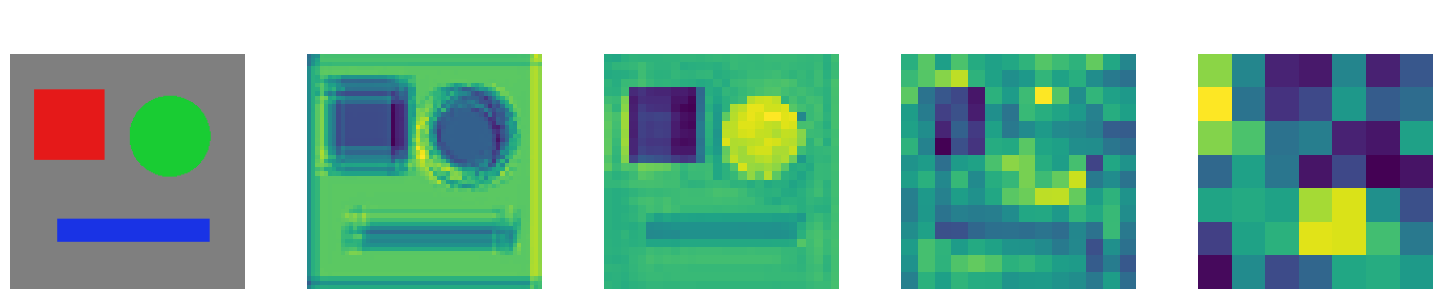

In [19]:
import matplotlib.pyplot as plt

def synthetic_image(size: int) -> torch.Tensor:
    """(1, 3, size, size) image with a red square, a green disc and a blue bar on grey."""
    yy, xx = torch.meshgrid(torch.linspace(0, 1, size), torch.linspace(0, 1, size), indexing="ij")
    img = torch.full((3, size, size), 0.5)
    sq = (xx > 0.1) & (xx < 0.4) & (yy > 0.15) & (yy < 0.45)
    disc = (xx - 0.68) ** 2 + (yy - 0.35) ** 2 < 0.03
    bar = (xx > 0.2) & (xx < 0.85) & (yy > 0.7) & (yy < 0.8)
    for mask, rgb in ((sq, (0.9, 0.1, 0.1)), (disc, (0.1, 0.8, 0.2)), (bar, (0.1, 0.2, 0.9))):
        for c in range(3):
            img[c][mask] = rgb[c]
    mean = torch.tensor([0.485, 0.456, 0.406])[:, None, None]
    std = torch.tensor([0.229, 0.224, 0.225])[:, None, None]
    return ((img - mean) / std)[None], img

name = next(iter(models))
inp, raw = synthetic_image(IMG)
with torch.no_grad():
    maps = models[name](inp).feature_maps
fig, axes = plt.subplots(1, len(maps) + 1, figsize=(3 * (len(maps) + 1), 3), facecolor="white")
axes[0].imshow(raw.permute(1, 2, 0)); axes[0].set_title("input", fontsize=9)
for ax, fm in zip(axes[1:], maps):
    ax.imshow(fm[0].mean(0), cmap="viridis")
    ax.set_title(f"{tuple(fm.shape[1:])} /{IMG // fm.shape[-1]}", fontsize=9)
for ax in axes:
    ax.axis("off")
plt.suptitle(f"{name}: channel-mean of every feature map", fontsize=11, fontweight="bold")
plt.tight_layout(); plt.show()

## 9. Experiments from the original walkthrough

The original notebook's hands-on cells, now running on the implementation defined in §4 (they used to import
`hale_core` through a relative `sys.path`, which only worked inside the HaleBlocks repo).

In [20]:
import sys
import numpy as np
import matplotlib.pyplot as plt

In [21]:
"""ConvNeXtV1Block walkthrough: compare with V2."""
import sys

import torch
import torch.nn as nn

# Demonstrate the difference: V1 block has no GRN, optionally has Layer Scale

v1_tiny_block   = ConvNeXtV1Block(dim=96, layer_scale_init_value=0.0)
v1_large_block  = ConvNeXtV1Block(dim=192, layer_scale_init_value=1e-6)
v2_block        = ConvNeXtV2Block(dim=96)

x = torch.randn(2, 96, 56, 56)  # stride-4 features from stem

print('Block parameter counts:')
def count(m): return sum(p.numel() for p in m.parameters())
print(f'  V1 tiny block  (dim=96,  no layer_scale):  {count(v1_tiny_block):,}')
print(f'  V1 large block (dim=192, layer_scale=1e-6): {count(v1_large_block):,}')
print(f'  V2 block       (dim=96,  with GRN):         {count(v2_block):,}')
print()

# V2 has GRN parameters (gamma + beta = 2 * 4*dim)
v2_extra = count(v2_block) - count(v1_tiny_block)
print(f'V2 extra params (GRN gamma+beta for 4*dim): {v2_extra}')
print(f'  Expected: 2 × 4 × 96 = {2*4*96}')

# Both produce same shape output
y1 = v1_tiny_block(x)
y2 = v2_block(x)
print(f'\nV1 output shape: {y1.shape}')
print(f'V2 output shape: {y2.shape}')

Block parameter counts:
  V1 tiny block  (dim=96,  no layer_scale):  79,200
  V1 large block (dim=192, layer_scale=1e-6): 306,048
  V2 block       (dim=96,  with GRN):         79,968

V2 extra params (GRN gamma+beta for 4*dim): 768
  Expected: 2 × 4 × 96 = 768

V1 output shape: torch.Size([2, 96, 56, 56])
V2 output shape: torch.Size([2, 96, 56, 56])


In [22]:
"""ConvNeXt V1 backbone usage."""
import torch

# List all V1 variants
v1_backbones = sorted([n for n in list_vision_backbones() if 'convnext_v1' in n])
print('ConvNeXt V1 variants:', v1_backbones)

# Compare V1 and V2 base side by side
v1_base = build_vision_backbone('convnext_v1_base', img_size=224)
v2_base = build_vision_backbone('convnext_base',    img_size=224)
v1_base.eval()
v2_base.eval()

x = torch.randn(2, 3, 224, 224)
with torch.no_grad():
    out1 = v1_base(x)
    out2 = v2_base(x)

print(f'\nConvNeXt V1 Base:')
print(f'  pooled_output: {out1.pooled_output.shape}')
print(f'  params: {v1_base.num_parameters()/1e6:.1f}M')
for i, fm in enumerate(out1.feature_maps):
    print(f'  stage {i}: {tuple(fm.shape)}')

print(f'\nConvNeXt V2 Base (for comparison):')
print(f'  pooled_output: {out2.pooled_output.shape}')
print(f'  params: {v2_base.num_parameters()/1e6:.1f}M')
print(f'  (V2 has slightly more params due to GRN gamma/beta)')

# Demonstrate stage freezing for fine-tuning
v1_base.freeze_up_to_stage(1)  # freeze stem + stage 0 + stage 1
trainable = v1_base.num_parameters(trainable_only=True)
total     = v1_base.num_parameters()
print(f'\nAfter freeze_up_to_stage(1):')
print(f'  trainable: {trainable:,} / {total:,} ({100*trainable/total:.1f}%)')

ConvNeXt V1 variants: ['convnext_v1_base', 'convnext_v1_large', 'convnext_v1_small', 'convnext_v1_tiny', 'convnext_v1_xlarge']



ConvNeXt V1 Base:
  pooled_output: torch.Size([2, 1024])
  params: 87.5M
  stage 0: (2, 128, 56, 56)
  stage 1: (2, 256, 28, 28)
  stage 2: (2, 512, 14, 14)
  stage 3: (2, 1024, 7, 7)

ConvNeXt V2 Base (for comparison):
  pooled_output: torch.Size([2, 1024])
  params: 87.7M
  (V2 has slightly more params due to GRN gamma/beta)

After freeze_up_to_stage(1):
  trainable: 84,853,248 / 87,548,416 (96.9%)


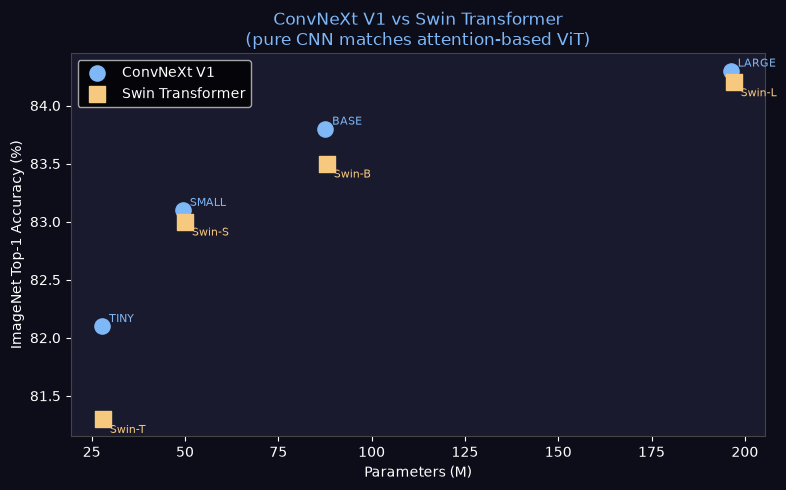

In [23]:
"""Compare V1 variants: accuracy vs parameters (published results)."""
import matplotlib.pyplot as plt
import torch

plt.style.use('dark_background')
ACCENT = '#7EB8F7'
GOLD   = '#F7C97E'

variants = [
    ('convnext_v1_tiny',   82.1, 'T'),
    ('convnext_v1_small',  83.1, 'S'),
    ('convnext_v1_base',   83.8, 'B'),
    ('convnext_v1_large',  84.3, 'L'),
]
# Also compare with Swin counterparts (from paper)
swin_variants = [
    ('Swin-T', 81.3, 28),
    ('Swin-S', 83.0, 50),
    ('Swin-B', 83.5, 88),
    ('Swin-L', 84.2, 197),
]

params_v1, accs_v1 = [], []
for name, acc, _ in variants:
    m = build_vision_backbone(name, img_size=224)
    params_v1.append(m.num_parameters() / 1e6)
    accs_v1.append(acc)

swin_params = [sv[2] for sv in swin_variants]
swin_accs   = [sv[1] for sv in swin_variants]
swin_labels = [sv[0] for sv in swin_variants]

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(params_v1, accs_v1, s=120, color=ACCENT, zorder=5, label='ConvNeXt V1')
for (name, acc, _), p in zip(variants, params_v1):
    ax.annotate(name.split('_')[-1].upper(), (p, acc), textcoords='offset points',
                xytext=(5, 3), fontsize=8, color=ACCENT)

ax.scatter(swin_params, swin_accs, s=120, color=GOLD, marker='s', zorder=5, label='Swin Transformer')
for label, acc, p in swin_variants:
    ax.annotate(label, (p, acc), textcoords='offset points',
                xytext=(5, -10), fontsize=8, color=GOLD)

ax.set_xlabel('Parameters (M)', color='white')
ax.set_ylabel('ImageNet Top-1 Accuracy (%)', color='white')
ax.set_title('ConvNeXt V1 vs Swin Transformer\n(pure CNN matches attention-based ViT)', color=ACCENT)
ax.legend()
ax.tick_params(colors='white')
for spine in ax.spines.values(): spine.set_color('#444')
ax.set_facecolor('#1a1a2e')
fig.patch.set_facecolor('#0d0d1a')
plt.tight_layout()
plt.show()

## References

1. **Liu, Z., Mao, H., Wu, C.-Y., Feichtenhofer, C., Darrell, T., & Xie, S. (2022).**  
   A ConvNet for the 2020s.  
   *CVPR 2022.* arXiv:2201.03545

2. **Woo, S., Debnath, S., Hu, R., Chen, X., Liu, Z., Kweon, I. S., & Xie, S. (2023).**  
   ConvNeXt V2: Co-designing and Scaling ConvNets with Masked Autoencoders.  
   *CVPR 2023.* arXiv:2301.00808

3. **Liu, Z., Lin, Y., Cao, Y., Hu, H., Wei, Y., Zhang, Z., ... & Guo, B. (2021).**  
   Swin Transformer: Hierarchical Vision Transformer using Shifted Windows.  
   *ICCV 2021.* arXiv:2103.14030

4. **He, K., Zhang, X., Ren, S., & Sun, J. (2016).**  
   Deep Residual Learning for Image Recognition.  
   *CVPR 2016.* arXiv:1512.03385

5. **Sandler, M., Howard, A., Zhu, M., Zhmoginov, A., & Chen, L.-C. (2018).**  
   MobileNetV2: Inverted Residuals and Linear Bottlenecks.  
   *CVPR 2018.* arXiv:1801.04381

6. **Touvron, H., Cord, M., Douze, M., Massa, F., Sablayrolles, A., & Jégou, H. (2021).**  
   Training data-efficient image transformers & distillation through attention (DeiT).  
   *ICML 2021.* arXiv:2012.12877